In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(context="notebook", style="whitegrid")


## Data

`n_samples` is per optimizer. The plots below therefore work from the summary table for the full search, and show fold-level detail only for the top configurations.

In [2]:
folds = pd.read_csv("../out/gridsearch/folds.csv")
results = pd.read_csv("../out/gridsearch/results.csv")

optimizer_order = sorted(results["optimizer"].unique())
palette = dict(zip(optimizer_order, sns.color_palette("colorblind", len(optimizer_order))))

summary_by_optimizer = (
    results.groupby("optimizer")
    .agg(
        n_configs=("config_id", "size"),
        mean_accuracy=("mean_val_accuracy", "mean"),
        best_accuracy=("mean_val_accuracy", "max"),
        median_fold_time_s=("mean_total_time_s", "median"),
    )
    .reindex(optimizer_order)
)

print(f"{len(results):,} configurations, {len(folds):,} fold rows")
summary_by_optimizer.round(4)


245 configurations, 1,225 fold rows


,n_configs,mean_accuracy,best_accuracy,median_fold_time_s
optimizer,,,,
adam,90,0.5203,0.8578,49.6555
muon,78,0.5457,0.8765,45.4191
sgd,77,0.5746,0.8486,43.8281


## Search overview

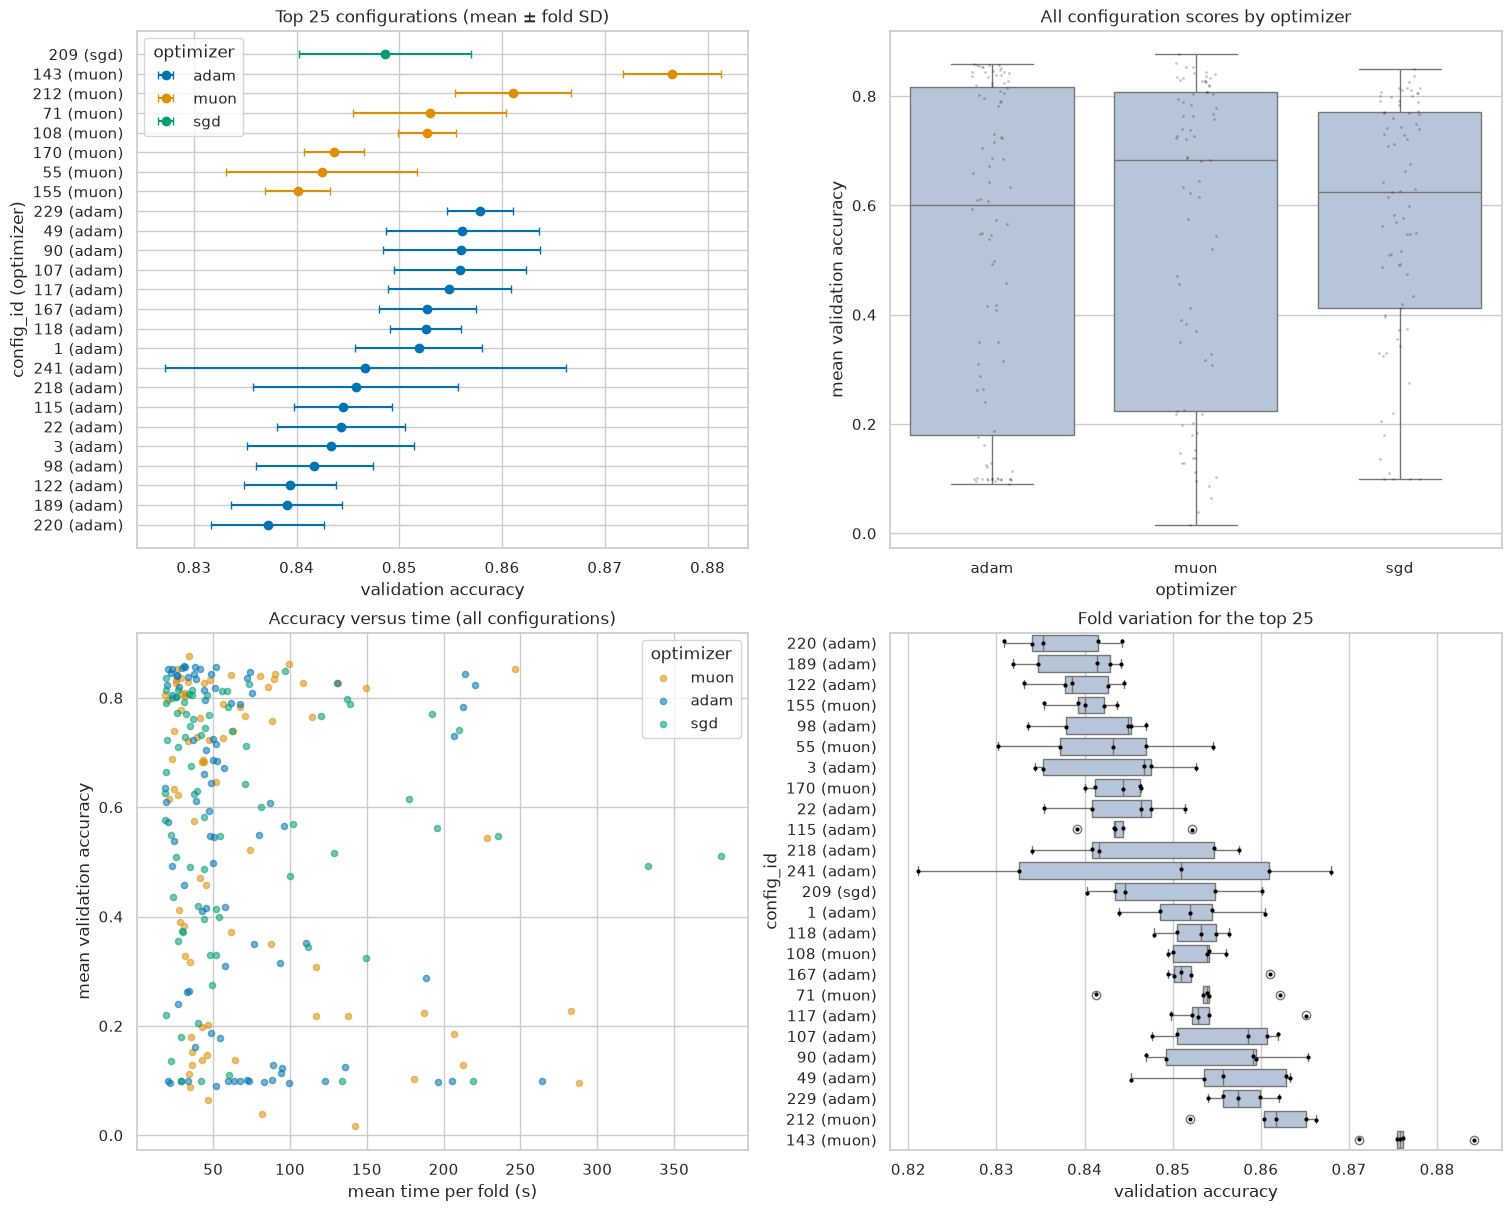

In [3]:
top_n = min(25, len(results))
top = results.nlargest(top_n, "mean_val_accuracy").sort_values("mean_val_accuracy")
top = top.assign(label=top.apply(lambda row: f"{row.config_id} ({row.optimizer})", axis=1))

fig, axes = plt.subplots(2, 2, figsize=(15, 12), constrained_layout=True)

for optimizer, group in top.groupby("optimizer", sort=False):
    axes[0, 0].errorbar(
        group["mean_val_accuracy"], group["label"], xerr=group["std_val_accuracy"],
        fmt="o", capsize=3, color=palette[optimizer], label=optimizer,
    )

axes[0, 0].set(
    title=f"Top {top_n} configurations (mean ± fold SD)", 
    xlabel="validation accuracy", 
    ylabel="config_id (optimizer)"
    )

axes[0, 0].legend(title="optimizer")

sns.boxplot(
    data=results, 
    x="optimizer", 
    y="mean_val_accuracy", 
    order=optimizer_order, 
    color="lightsteelblue", 
    ax=axes[0, 1]
    )

sns.stripplot(
    data=results, 
    x="optimizer", 
    y="mean_val_accuracy", 
    order=optimizer_order, 
    color="black", 
    alpha=0.22, 
    size=2, 
    ax=axes[0, 1]
    )

axes[0, 1].set(
    title="All configuration scores by optimizer", 
    xlabel="optimizer", 
    ylabel="mean validation accuracy"
    )

for optimizer, group in results.groupby("optimizer", sort=False):
    axes[1, 0].scatter(
        group["mean_total_time_s"], 
        group["mean_val_accuracy"], 
        s=20, 
        alpha=0.55, 
        color=palette[optimizer], 
        label=optimizer
        )
    
axes[1, 0].set(
    title="Accuracy versus time (all configurations)", 
    xlabel="mean time per fold (s)", 
    ylabel="mean validation accuracy"
    )

axes[1, 0].legend(title="optimizer")

top_folds = folds[folds["config_id"].isin(top["config_id"])].copy()
labels_by_config = top.set_index("config_id")["label"]
top_folds["label"] = top_folds["config_id"].map(labels_by_config)
fold_order = top["label"].tolist()

sns.boxplot(
    data=top_folds, 
    y="label", 
    x="val_accuracy", 
    order=fold_order, 
    color="lightsteelblue", 
    ax=axes[1, 1]
    )

sns.stripplot(
    data=top_folds, 
    y="label", 
    x="val_accuracy", 
    order=fold_order, 
    color="black", 
    size=3, 
    ax=axes[1, 1]
    )

axes[1, 1].set(
    title=f"Fold variation for the top {top_n}", 
    xlabel="validation accuracy", 
    ylabel="config_id"
    )

plt.show()


## Hyperparameters versus accuracy

Each point is one cross-validated configuration. Colour makes it possible to see whether a parameter range behaves differently for an optimizer.

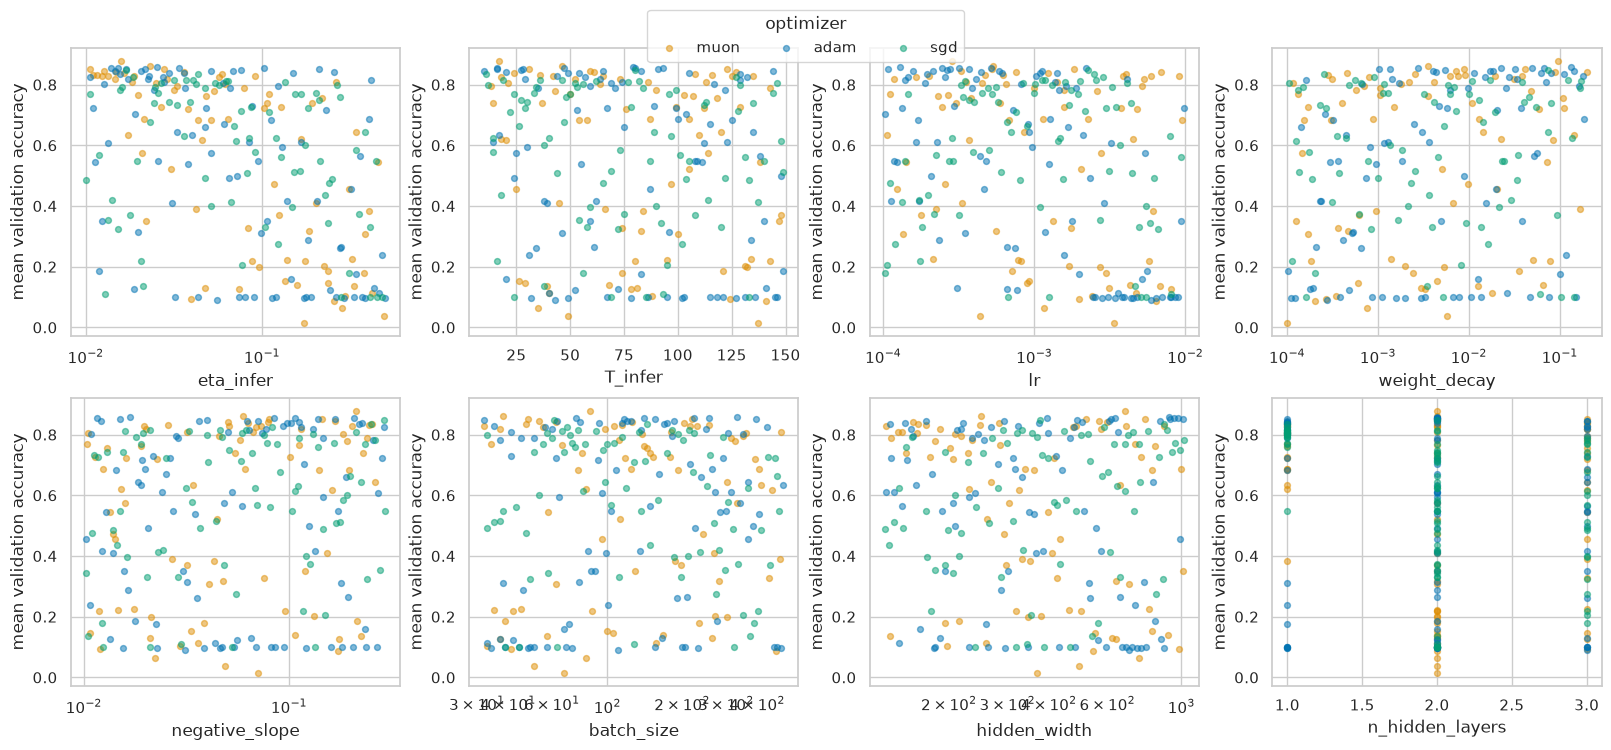

In [4]:
params = [
    "eta_infer", "T_infer", "lr", "weight_decay",
    "negative_slope", "batch_size", "hidden_width", "n_hidden_layers",
]
log_params = {"eta_infer", "lr", "weight_decay", "negative_slope", "batch_size", "hidden_width"}

fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for ax, param in zip(axes.ravel(), params):
    for optimizer, group in results.groupby("optimizer", sort=False):
        ax.scatter(
            group[param], 
            group["mean_val_accuracy"], 
            s=18, 
            alpha=0.5, 
            color=palette[optimizer], 
            label=optimizer
            )
    if param in log_params:
        ax.set_xscale("log")
    ax.set(xlabel=param, ylabel="mean validation accuracy")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="optimizer", loc="upper center", ncol=len(optimizer_order), bbox_to_anchor=(0.5, 1.06))
plt.show()


## Search convergence

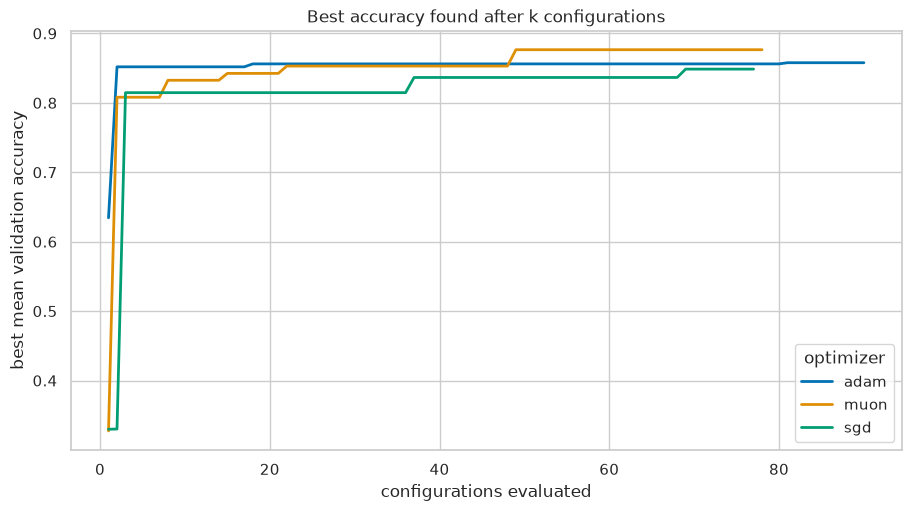

In [5]:
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)

for optimizer in optimizer_order:
    group = results[results["optimizer"] == optimizer].sort_values("config_id")
    ax.plot(
        range(1, len(group) + 1),
        group["mean_val_accuracy"].cummax(),
        color=palette[optimizer],
        label=optimizer,
        linewidth=2,
    )

ax.set(
    title="Best accuracy found after k configurations",
    xlabel="configurations evaluated",
    ylabel="best mean validation accuracy",
)

ax.legend(title="optimizer")
plt.show()

## Hyperparameter influence

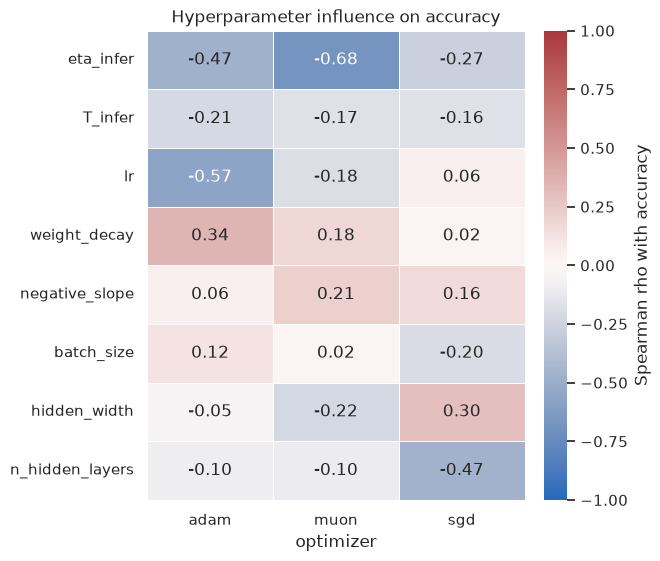

In [6]:
influence = pd.DataFrame({
    optimizer: results[results["optimizer"] == optimizer][params].corrwith(
        results[results["optimizer"] == optimizer]["mean_val_accuracy"], method="spearman"
    )
    for optimizer in optimizer_order
})

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)

sns.heatmap(
    influence,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Spearman rho with accuracy"},
    ax=ax,
)

ax.set(title="Hyperparameter influence on accuracy", xlabel="optimizer", ylabel="")
plt.show()

## Inference relaxation

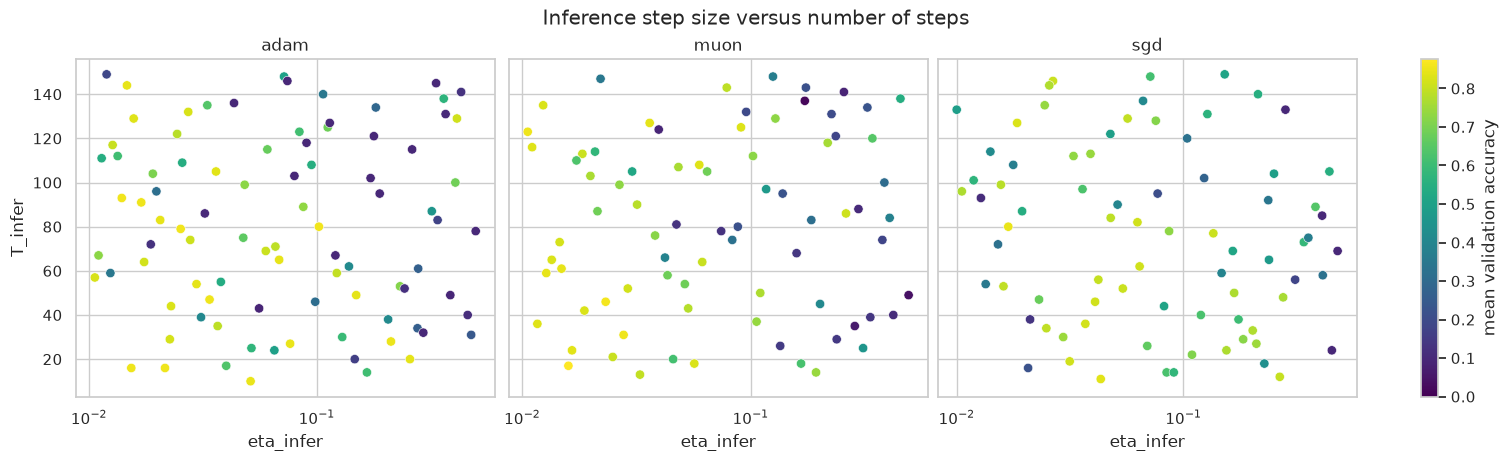

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True, constrained_layout=True)

for ax, optimizer in zip(axes, optimizer_order):
    group = results[results["optimizer"] == optimizer]
    dots = ax.scatter(
        group["eta_infer"],
        group["T_infer"],
        c=group["mean_val_accuracy"],
        cmap="viridis",
        vmin=0,
        vmax=results["mean_val_accuracy"].max(),
        s=45,
        edgecolor="white",
        linewidth=0.4,
    )
    ax.set(xscale="log", title=optimizer, xlabel="eta_infer")

axes[0].set_ylabel("T_infer")
fig.colorbar(dots, ax=axes, label="mean validation accuracy")
fig.suptitle("Inference step size versus number of steps")
plt.show()

## Stability

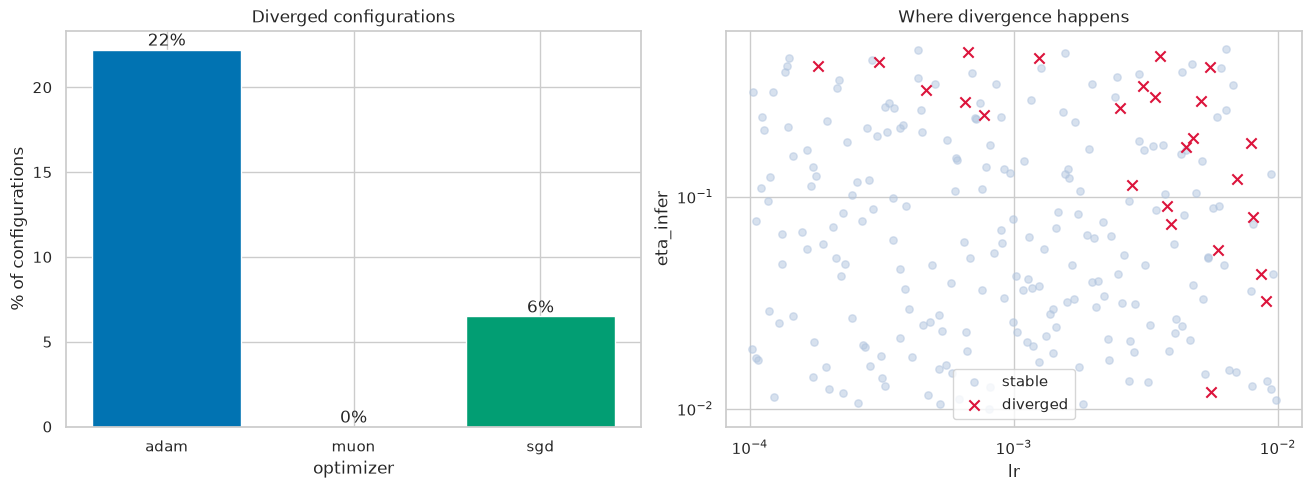

In [8]:
results["diverged"] = ~np.isfinite(results["mean_val_free_energy"])
stable = results[~results["diverged"]]
blown = results[results["diverged"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

rate = 100 * results.groupby("optimizer")["diverged"].mean().reindex(optimizer_order)
bars = axes[0].bar(rate.index, rate.values, color=[palette[o] for o in optimizer_order])
axes[0].bar_label(bars, fmt="%.0f%%")

axes[0].set(
    title="Diverged configurations",
    xlabel="optimizer",
    ylabel="% of configurations",
)

axes[1].scatter(
    stable["lr"], stable["eta_infer"],
    s=28, alpha=0.5, color="lightsteelblue", label="stable",
)

axes[1].scatter(
    blown["lr"], blown["eta_infer"],
    s=55, color="crimson", marker="x", label="diverged",
)

axes[1].set(
    xscale="log",
    yscale="log",
    title="Where divergence happens",
    xlabel="lr",
    ylabel="eta_infer",
)

axes[1].legend()
plt.show()

## Energies versus accuracy

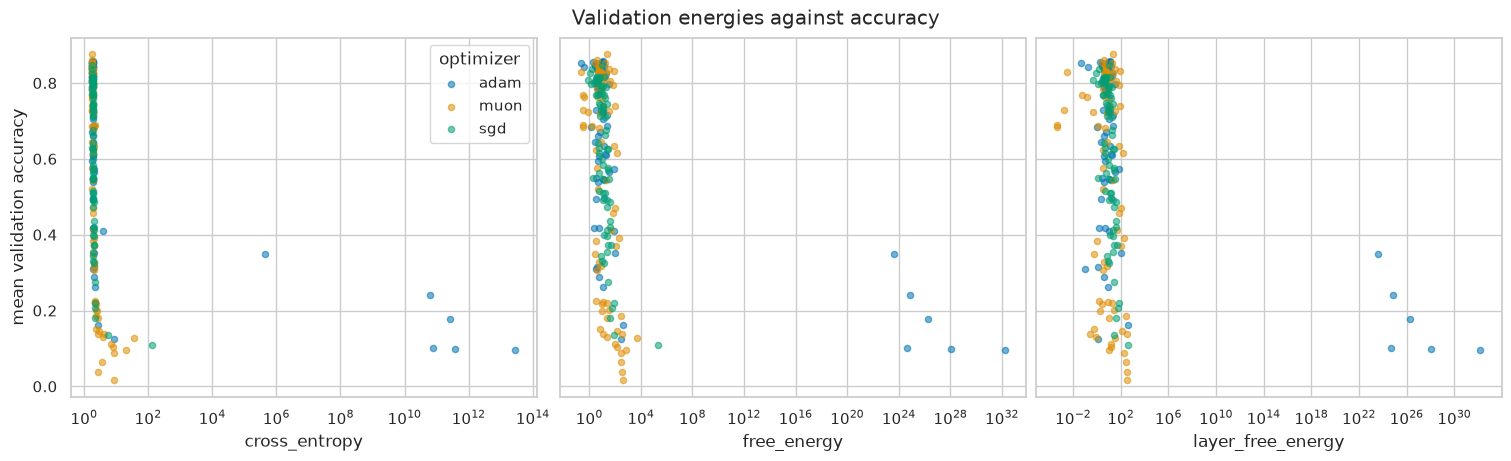

In [9]:
energies = ["mean_val_cross_entropy", "mean_val_free_energy", "mean_val_layer_free_energy"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True, constrained_layout=True)

for ax, energy in zip(axes, energies):
    for optimizer in optimizer_order:
        group = stable[stable["optimizer"] == optimizer]
        ax.scatter(
            group[energy],
            group["mean_val_accuracy"],
            s=20,
            alpha=0.55,
            color=palette[optimizer],
            label=optimizer,
        )
    ax.set(xscale="log", xlabel=energy.replace("mean_val_", ""))

axes[0].set_ylabel("mean validation accuracy")
axes[0].legend(title="optimizer")
fig.suptitle("Validation energies against accuracy")
plt.show()

## Architecture and cost

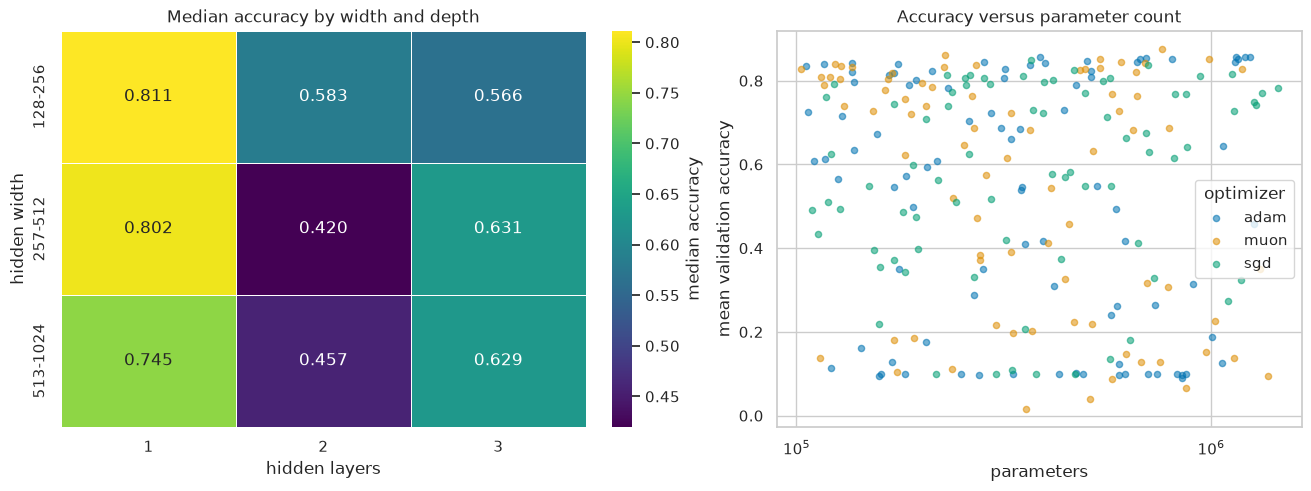

In [10]:
width_bins = pd.cut(
    results["hidden_width"],
    [128, 256, 512, 1024],
    labels=["128-256", "257-512", "513-1024"],
    include_lowest=True,
)

grid = results.pivot_table(
    index=width_bins,
    columns="n_hidden_layers",
    values="mean_val_accuracy",
    aggfunc="median",
    observed=True,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

sns.heatmap(
    grid,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    linewidths=0.5,
    cbar_kws={"label": "median accuracy"},
    ax=axes[0],
)

axes[0].set(
    title="Median accuracy by width and depth",
    xlabel="hidden layers",
    ylabel="hidden width",
)

for optimizer in optimizer_order:
    group = results[results["optimizer"] == optimizer]
    axes[1].scatter(
        group["n_params"],
        group["mean_val_accuracy"],
        s=20,
        alpha=0.55,
        color=palette[optimizer],
        label=optimizer,
    )

axes[1].set(
    xscale="log",
    title="Accuracy versus parameter count",
    xlabel="parameters",
    ylabel="mean validation accuracy",
)

axes[1].legend(title="optimizer")
plt.show()

## Best configurations


In [11]:
columns = [
    "config_id", "optimizer", "dims", "eta_infer", "T_infer", "lr", "weight_decay",
    "negative_slope", "batch_size", "mean_val_accuracy", "std_val_accuracy",
    "mean_val_f1_macro", "mean_total_time_s",
]
results.nlargest(20, "mean_val_accuracy")[columns].round(4)


,config_id,optimizer,dims,eta_infer,T_infer,lr,weight_decay,negative_slope,batch_size,mean_val_accuracy,std_val_accuracy,mean_val_f1_macro,mean_total_time_s
0,143,muon,"(784, 675, 337)",0.0159,17,0.0003,0.0953,0.2113,85,0.8765,0.0047,0.8748,34.0878
1,212,muon,"(784, 250, 125)",0.0232,46,0.0005,0.0036,0.0598,38,0.8611,0.0057,0.8590,99.6500
2,229,adam,"(784, 921, 460)",0.0253,79,0.0001,0.1342,0.0168,330,0.8578,0.0032,0.8553,31.1566
3,49,adam,"(784, 975, 487)",0.0139,93,0.0003,0.0492,0.0117,256,0.8561,0.0074,0.8534,38.3376
4,90,adam,"(784, 954, 477)",0.1023,80,0.0002,0.0227,0.1070,140,0.8560,0.0077,0.8530,51.5398
5,107,adam,"(784, 393, 196)",0.0154,16,0.0005,0.0027,0.0849,75,0.8559,0.0064,0.8534,31.8937
6,117,adam,"(784, 630, 315)",0.0339,47,0.0022,0.0676,0.2065,222,0.8548,0.0060,0.8519,29.6408
7,71,muon,"(784, 777, 388, 194)",0.0106,123,0.0018,0.0417,0.1454,48,0.8530,0.0075,0.8504,246.2806
8,167,adam,"(784, 614, 307)",0.0216,16,0.0004,0.0010,0.1681,156,0.8527,0.0047,0.8502,23.5254
9,108,muon,"(784, 516, 258)",0.0278,31,0.0005,0.0088,0.0803,218,0.8527,0.0028,0.8502,26.3073
